In [66]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

In [67]:
import glob
import os

import matplotlib as mpl
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- fonts
FONT_DIR = os.path.expanduser("~/fonts/SourceSans3")

for f in glob.glob(os.path.join(FONT_DIR, "*.ttf")):
    fm.fontManager.addfont(f)

available = {f.name for f in fm.fontManager.ttflist}
FAMILY = next((n for n in ("Source Sans 3", "Source Sans Pro") if n in available), None)
if FAMILY is None:
    raise RuntimeError(f"Source Sans not found. Check FONT_DIR: {FONT_DIR}")

# ---------------------------------------------------------------- sizes
W = 418.25372 / 72.27   # \textwidth in inches (~5.787)
W_HALF = 0.48 * W       # two panels side by side

mpl.rcParams.update({
    # --- Text / fonts ---
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": [FAMILY],
    "mathtext.fontset": "custom",
    "mathtext.rm": FAMILY,
    "mathtext.it": f"{FAMILY}:italic",
    "mathtext.bf": f"{FAMILY}:bold",
    "mathtext.sf": FAMILY,
    "mathtext.default": "it",
    "mathtext.fallback": "cm",       # fallback for missing math glyphs
    "axes.unicode_minus": True,      # Source Sans has the proper minus sign

    # --- Font sizes (pt), matched to 11 pt body text ---
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.titlesize": 10,

    # --- Lines, markers, axes ---
    "axes.linewidth": 0.8,
    "lines.linewidth": 1.3,
    "lines.markersize": 4,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.4,

    # --- Legend ---
    "legend.frameon": False,
    "legend.handlelength": 1.5,

    # --- Layout and output ---
    "figure.figsize": (W, W),
    "figure.constrained_layout.use": True,
    "savefig.dpi": 300,              # only matters for raster output
    "savefig.format": "pdf",
    "pdf.fonttype": 42,              # embed TrueType, no Type 3
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

In [68]:
runs=['oper_01', 'oper_02']

In [69]:
ht = xr.open_mfdataset([f'/jetfs/scratch/psplechtna/thesisdata/oper/2024/heighttest_{run}.nc' for run in runs])

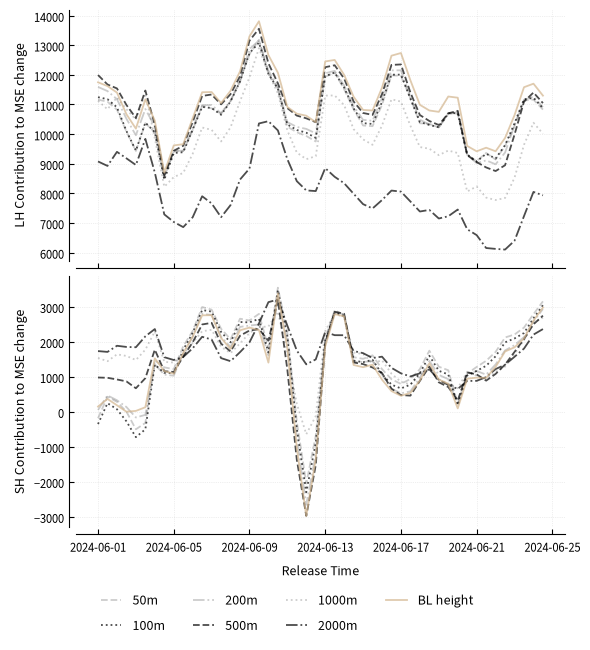

In [74]:
xes = ht['lh_per_rel'].release_time

fig, ax = plt.subplots(2, 1, sharex=True)


ax[0].plot(xes, ht['lh_per_rel'].sel(level='50.0'), color='k', linestyle='--', alpha=0.2, label='50m')
ax[0].plot(xes, ht['lh_per_rel'].sel(level='100.0'), color='k', linestyle=':', alpha=0.7, label='100m')
ax[0].plot(xes, ht['lh_per_rel'].sel(level='200.0'), color='k', linestyle='-.', alpha=0.2, label='200m')
ax[0].plot(xes, ht['lh_per_rel'].sel(level='500.0'), color='k', linestyle='--', alpha=0.7, label='500m')
ax[0].plot(xes, ht['lh_per_rel'].sel(level='1000.0'), color='k', linestyle=':', alpha=0.2, label='1000m')
ax[0].plot(xes, ht['lh_per_rel'].sel(level='2000.0'), color='k', linestyle='-.', alpha=0.7, label='2000m')
ax[0].plot(xes, ht['lh_per_rel'].sel(level='bl'), color='tan', linestyle='-', alpha=0.7, label='BL height')

ax[0].set_ylabel('LH Contribution to MSE change')


ax[1].plot(xes, ht['sh_per_rel'].sel(level='50.0'), color='k', linestyle='--', alpha=0.2)
ax[1].plot(xes, ht['sh_per_rel'].sel(level='100.0'), color='k', linestyle=':', alpha=0.7)
ax[1].plot(xes, ht['sh_per_rel'].sel(level='200.0'), color='k', linestyle='-.', alpha=0.2)
ax[1].plot(xes, ht['sh_per_rel'].sel(level='500.0'), color='k', linestyle='--', alpha=0.7)
ax[1].plot(xes, ht['sh_per_rel'].sel(level='1000.0'), color='k', linestyle=':', alpha=0.2)
ax[1].plot(xes, ht['sh_per_rel'].sel(level='2000.0'), color='k', linestyle='-.', alpha=0.7)
ax[1].plot(xes, ht['sh_per_rel'].sel(level='bl'), color='tan', linestyle='-', alpha=0.7)

ax[1].set_xlabel('Release Time')
ax[1].set_ylabel('SH Contribution to MSE change')

for axs in ax:
    for spine in ['top', 'right']:
        axs.spines[spine].set_visible(False)
    spine_offset=5
    axs.spines.left.set_position(('outward', spine_offset))
    axs.spines.bottom.set_position(('outward', spine_offset))
    axs.grid(linestyle=':')
    

fig.legend(bbox_to_anchor=(0.83, 0.01), ncol=4, frameon=True, framealpha=1, edgecolor='white', fontsize=10)

#fig.savefig('/jetfs/home/psplechtna/plots/heighttest.pdf')